In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../'))
sys.path.append(base_path)

import numpy as np
import matplotlib.pyplot as plt  
import pandas as pd
from tqdm import tqdm
import pandas as pd
from IPython.display import display


import project_images_loader as pil
import utils.util as util
import utils.functions as fc
import utils.nifti_functions as nfc

import utils.util_freesurfer_segmentation as util_freesurfer
from PIL import Image
import random

np.set_printoptions(precision=4)

%matplotlib widget


# Load images

In [2]:
def load_img_and_mask(id, hunt):
    # img_path_name = pil.get_registered_to_template_image_path_name(hunt, id, pil.REGISTRATION_TO_MNI, absolute=True)
    img_path_name = pil.get_preprocessed_image_path_name(hunt, id, absolute=True)
    mask_path_name = pil.get_brain_mask_path_name(hunt, id, pil.REGISTRATION_TO_MNI, no_cerebellum=False, absolute=True)

    img, _ = nfc.load_nifti(img_path_name)
    mask, _ = nfc.load_nifti(mask_path_name)
    return img, mask

# Similarity by resizing

0: {'rms': 3.795670551986519e-05, 'ncc': 0.9636159840372291, 'mi': -0.9119209261273422, 'ssim': 0.9319333324693926}


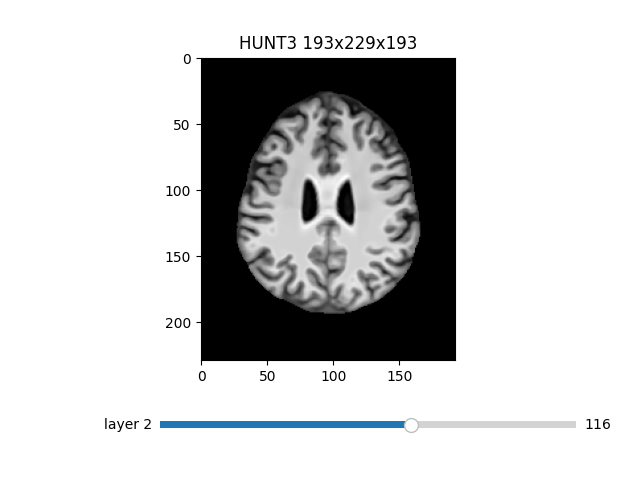

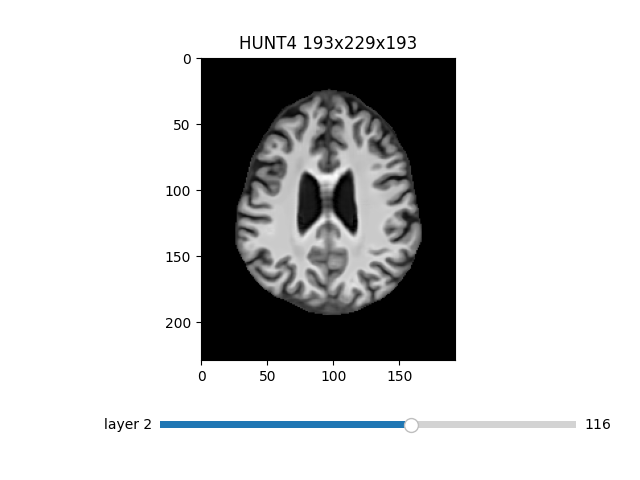

1: {'rms': 0.00011153101739013347, 'ncc': 0.9655970875155445, 'mi': -1.2223980428115269, 'ssim': 0.9432943915215319}


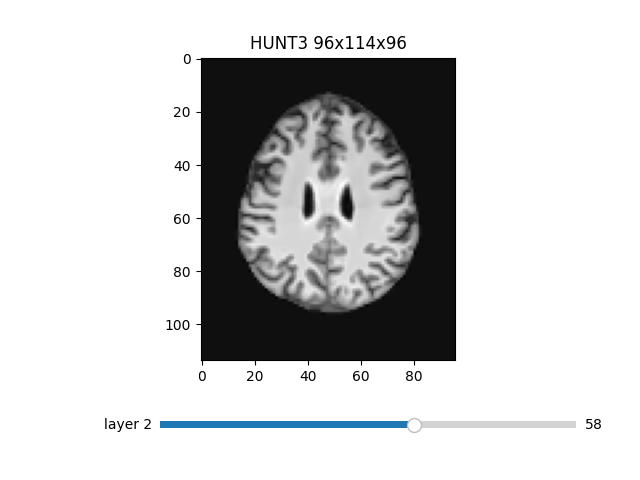

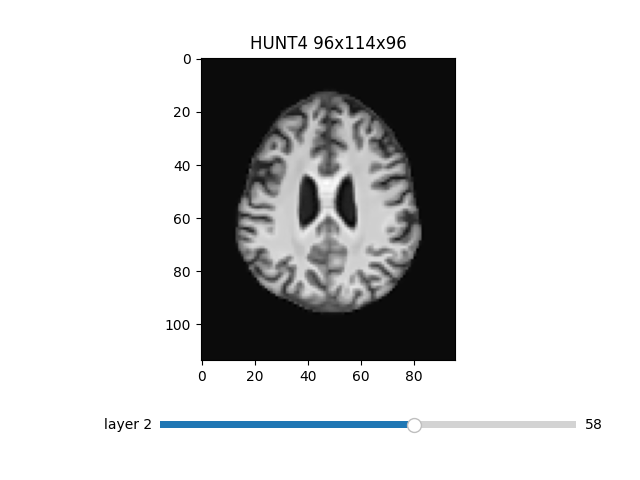

2: {'rms': 0.0003086639352117967, 'ncc': 0.9669335681946729, 'mi': -0.9491988525155275, 'ssim': 0.9406668306780869}


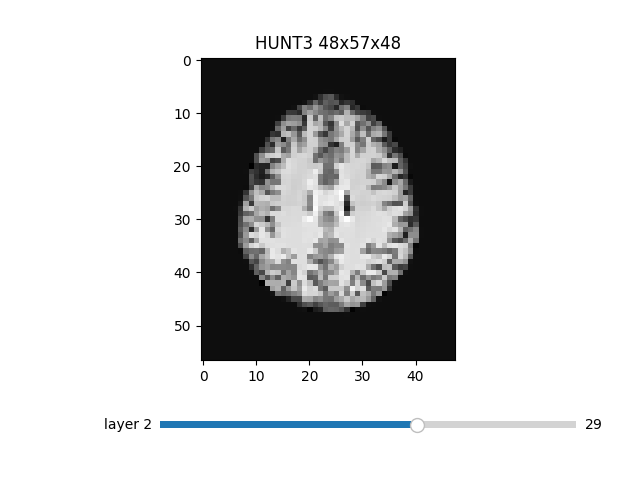

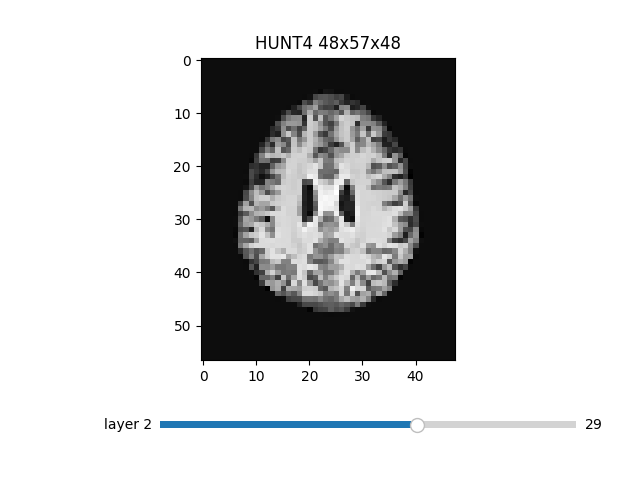

3: {'rms': 0.0008486707334579858, 'ncc': 0.9698795349099328, 'mi': -0.09802467351439059, 'ssim': 0.9475506315220038}


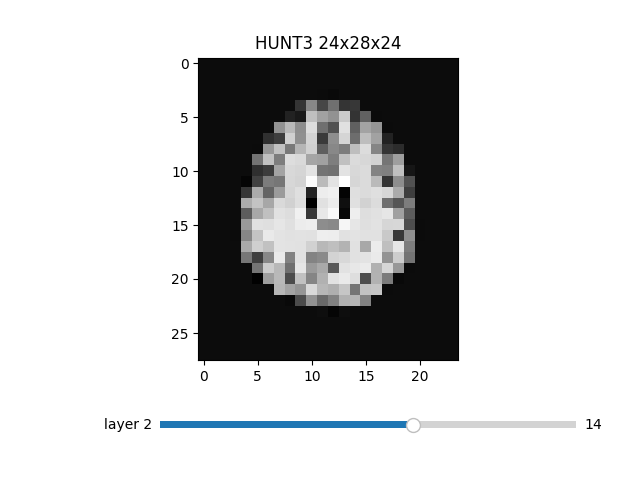

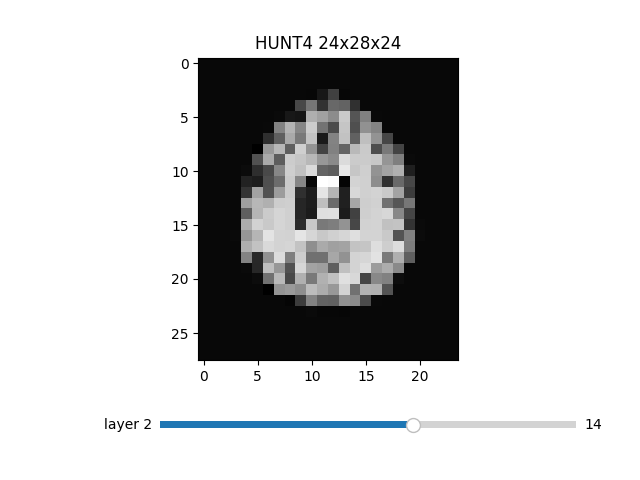

In [3]:

def compute_similarity_by_resizing(id="00046"):

    img_h3 , mask_h3 = load_img_and_mask(id, 3)
    img_h4 , mask_h4 = load_img_and_mask(id, 4)

    for i in range(4):
        new_shape = img_h3.shape[0]//2**i, img_h3.shape[1]//2**i, img_h3.shape[2]//2**i
        # new_shape = img_h3.shape[0]*2**i, img_h3.shape[1]*2**i, img_h3.shape[2]*2**i
        _n_hunt3 = util.resize_3D_image(img_h3, new_shape)
        _n_hunt4 = util.resize_3D_image(img_h4, new_shape)

        _metrics = util.get_metrics_dict(_n_hunt3, _n_hunt4)
        print(f"{i}: {_metrics}")

        str_size = 'x'.join([str(i) for i in new_shape])
        fc.imgshow_3D(f"HUNT3 {str_size}", _n_hunt3, current_plane=116//2**i)
        fc.imgshow_3D(f"HUNT4 {str_size}", _n_hunt4, current_plane=116//2**i)

# 0: {'rms': 0.0062310309534952405, 'ncc': 0.8695290238395318, 'mi': 1.2684474035931537, 'ssim': 0.7099899383195897}
# 1: {'rms': 0.017698444933746935, 'ncc': 0.8707665952290938, 'mi': 1.3027996293331068, 'ssim': 0.729228514512855}
# 2: {'rms': 0.04965002729288177, 'ncc': 0.8739510834413127, 'mi': 1.5229310319460811, 'ssim': 0.7760415845409878}
# 3: {'rms': 0.13942425314361592, 'ncc': 0.8797536389957515, 'mi': 2.3222506522640707, 'ssim': 0.8456056317818963}

compute_similarity_by_resizing("00046")

# Similarity by adding noise

In [4]:
def add_noise(img, img2, mean=0.5, std=0.1, add=False, normalize=True):
    noise = np.random.normal(loc=mean, scale=std, size=img.shape)
    if add:
        img = img + noise
        img2 = img2 + noise
    else:
        img = img * noise
        img2 = img2 * noise

    if normalize:
        img = util.normalize(util.standarize(img))
        img2 = util.normalize(util.standarize(img2))
    return img, img2

0: 0.9319333324693923


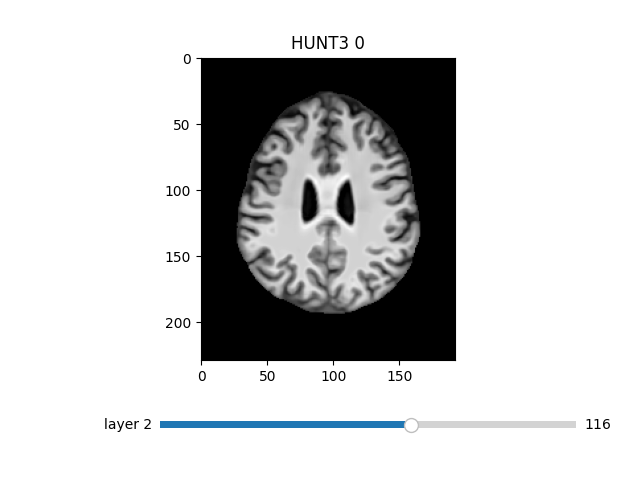

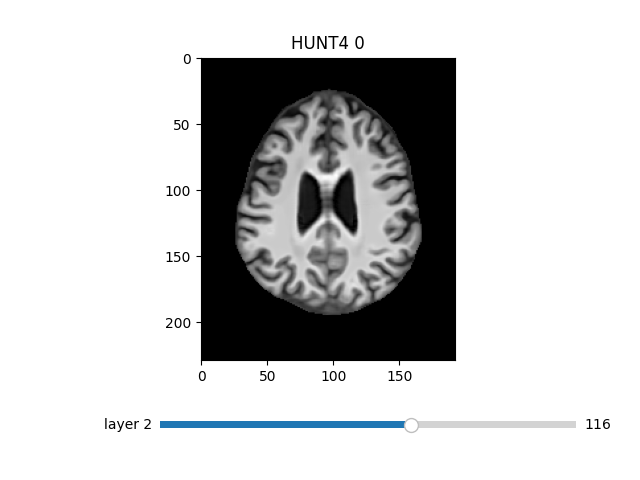

1: 0.9697263543108567


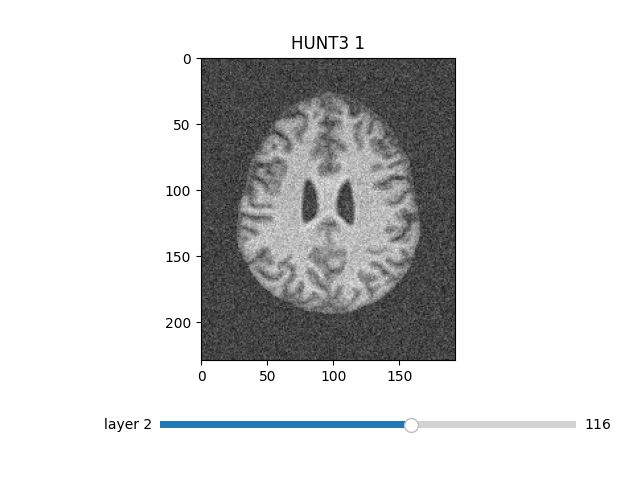

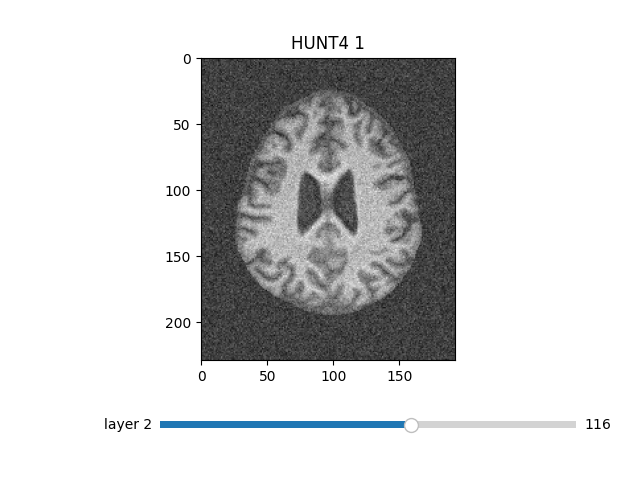

2: 0.9856018902227256


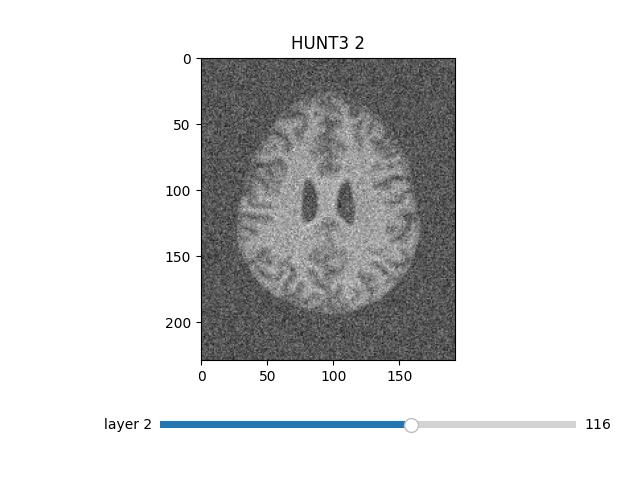

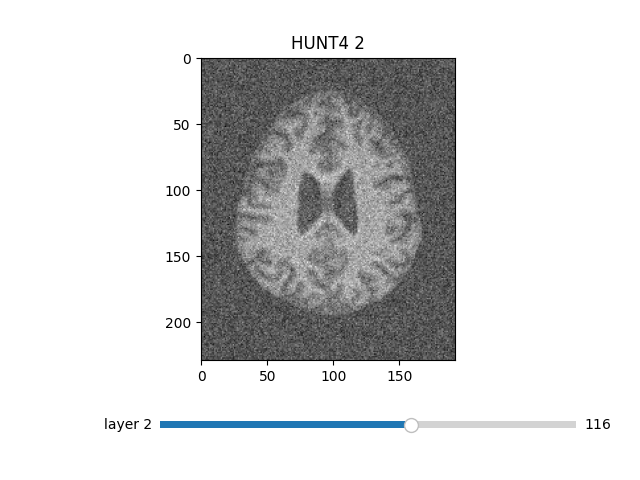

3: 0.9935235482315912


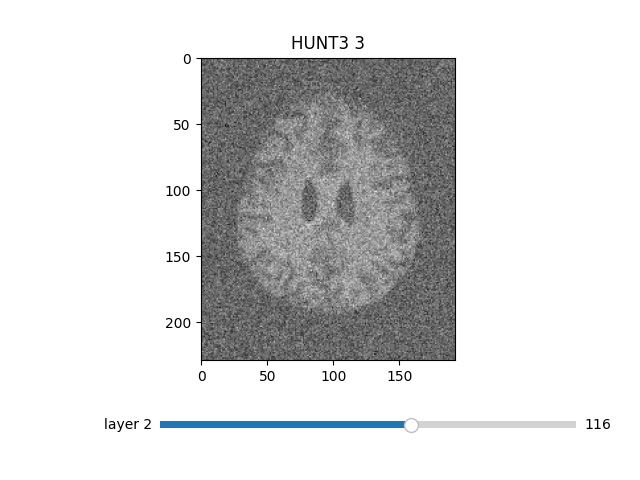

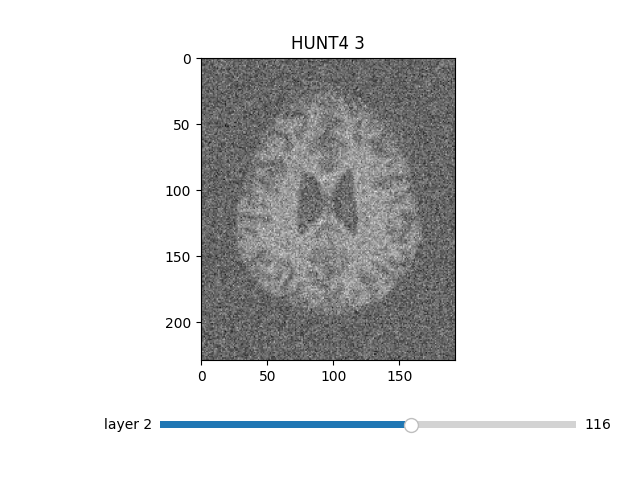

In [5]:
def compute_similarity_by_resizing(id="00046"):

    img_h3 , mask_h3 = load_img_and_mask(id, 3)
    img_h4 , mask_h4 = load_img_and_mask(id, 4)

    for i in range(4):
        if i > 0:
            img_h3, img_h4 = add_noise(img_h3, img_h4, mean=0.5, std=0.1, add=True, normalize=True)

        _metrics = util.compute_ssim(img_h3, img_h4)
        print(f"{i}: {_metrics}")

        fc.imgshow_3D(f"HUNT3 {i}", img_h3, current_plane=116)
        fc.imgshow_3D(f"HUNT4 {i}", img_h4, current_plane=116)

# 0: 0.9319333324693923
# 1: 0.9506813823342845
# 2: 0.9586158648445027
# 3: 0.9640896119300277
# 4: 0.9669480465205049
# 5: 0.9713112681705562
# 6: 0.9712429363925605
# 7: 0.9792503909679203
# 8: 0.9810389742813661
# 9: 0.9718736252142516

compute_similarity_by_resizing("00046")

# Similarity by resizing and adding noise

0: 0.9319333324693926


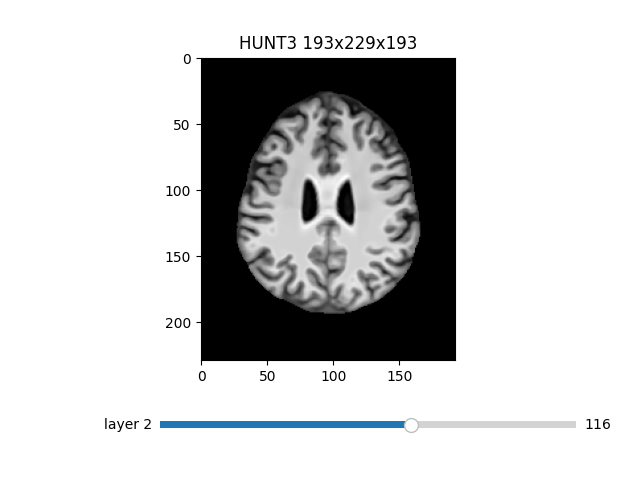

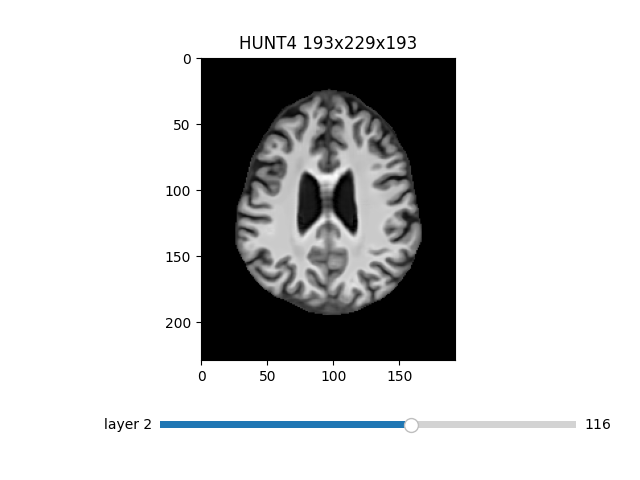

1: 0.9288916053089803


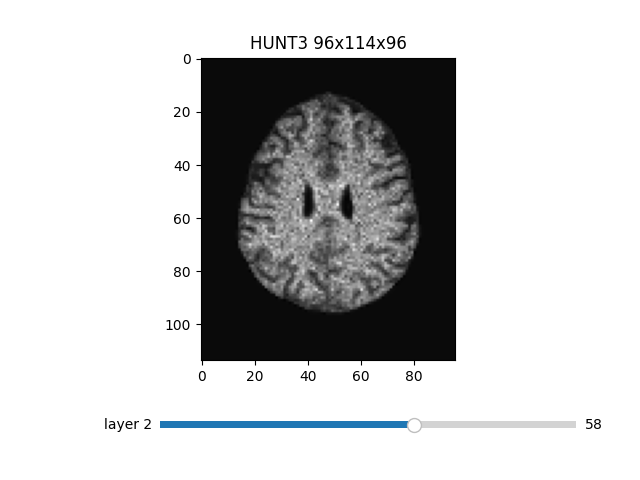

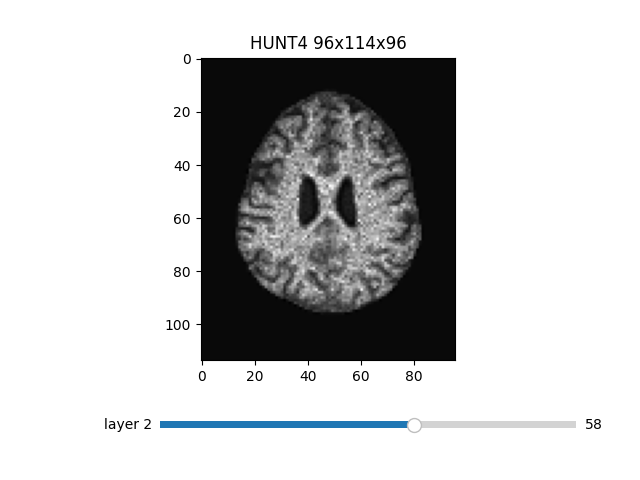

2: 0.9441078061749179


More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.


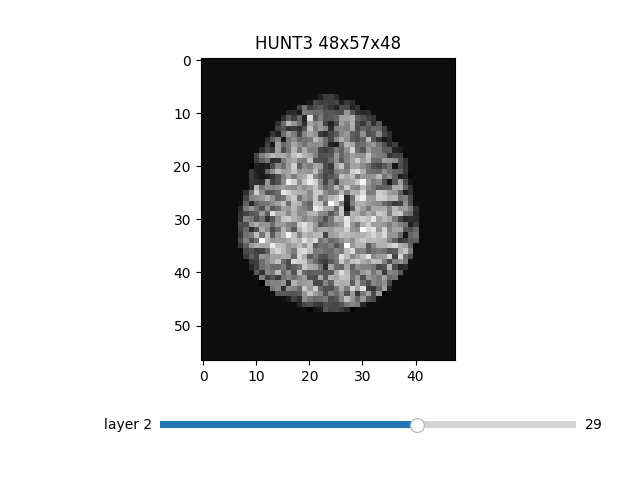

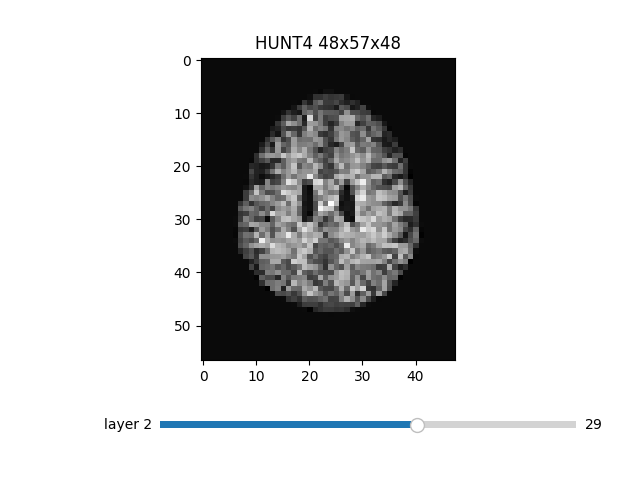

3: 0.9504098713469584


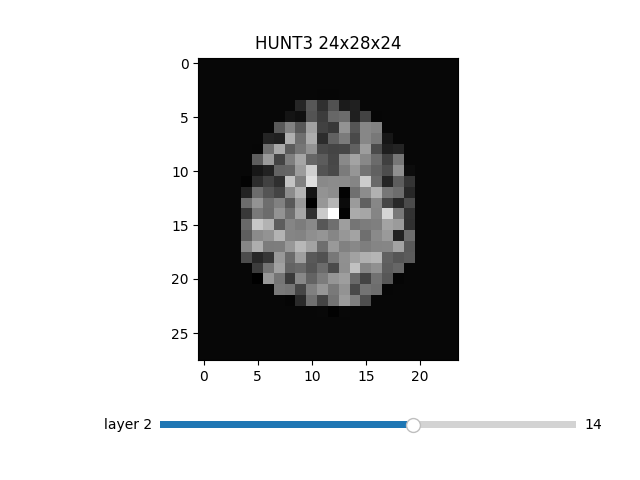

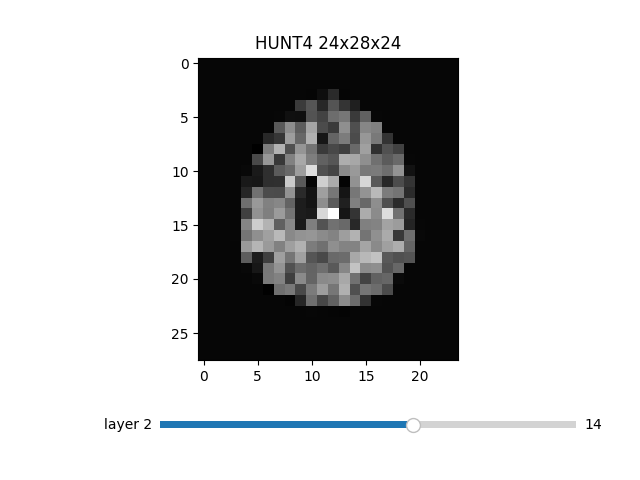

In [6]:
def compute_similarity_by_resizing_and_adding_noise(id="00046"):

    img_hunt3 , mask_h3 = load_img_and_mask(id, 3)
    img_hunt4 , mask_h4 = load_img_and_mask(id, 4)

    for i in range(4):
        new_shape = img_hunt3.shape[0]//2**i, img_hunt3.shape[1]//2**i, img_hunt3.shape[2]//2**i
        _n_hunt3 = util.resize_3D_image(img_hunt3, new_shape)
        _n_hunt4 = util.resize_3D_image(img_hunt4, new_shape)

        if i > 0:
            _n_hunt3, _n_hunt4 = add_noise(_n_hunt3, _n_hunt4, mean=0.5, std=0.1, add=False, normalize=True)
        
        _metrics = util.compute_ssim(_n_hunt3, _n_hunt4)
        print(f"{i}: {_metrics}")

        str_size = 'x'.join([str(i) for i in new_shape])
        fc.imgshow_3D(f"HUNT3 {str_size}", _n_hunt3, current_plane=116//2**i)
        fc.imgshow_3D(f"HUNT4 {str_size}", _n_hunt4, current_plane=116//2**i)

compute_similarity_by_resizing_and_adding_noise("00046")

#  aditive
# 0: 0.9319333324693926
# 1: 0.9713088324429571
# 2: 0.965908660118233
# 3: 0.9643448975086345

# multiplicative
# 0: 0.9319333324693926
# 1: 0.9380345865438784
# 2: 0.934040700272704
# 3: 0.9561751740723371

0: 0.9319333324693923


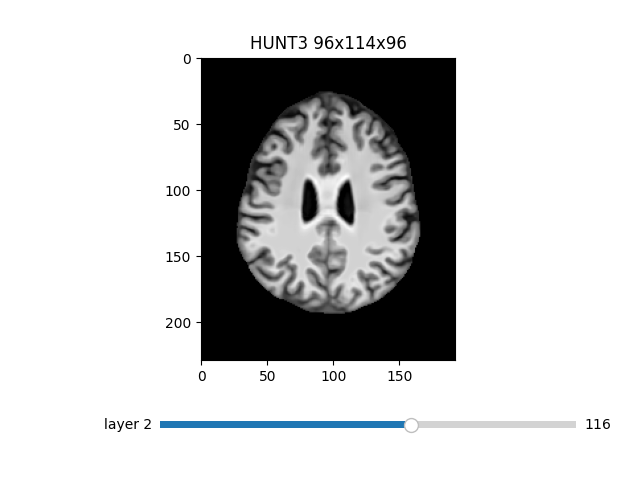

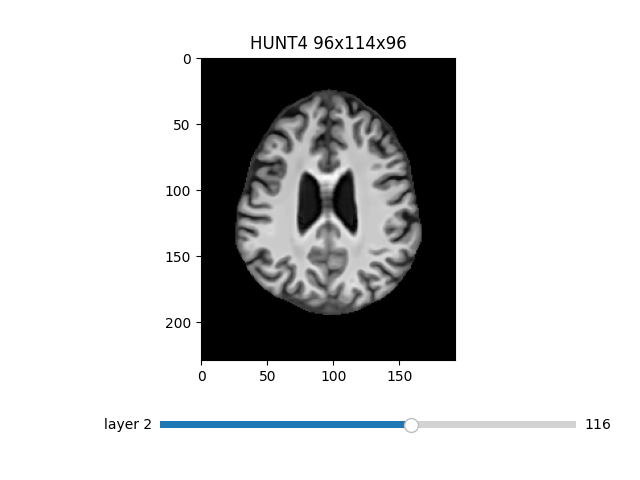

1: 0.9693359854366806


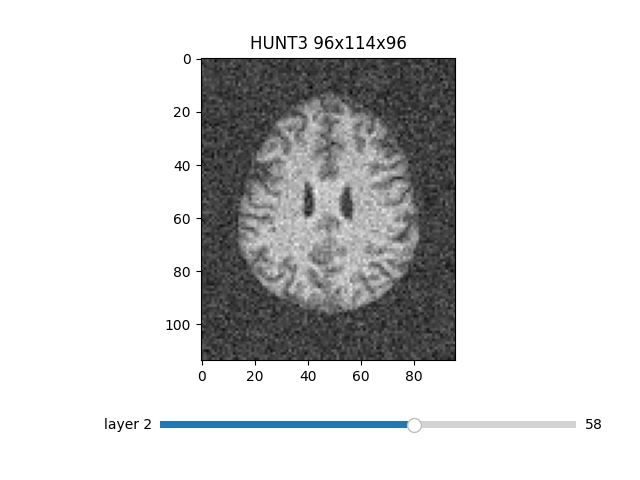

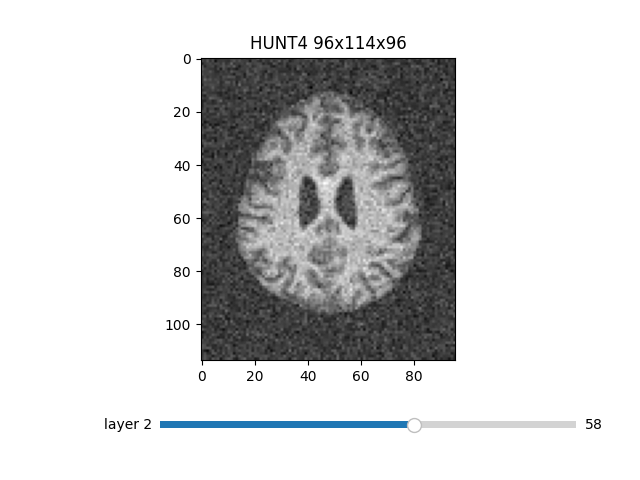

2: 0.9841035338603797


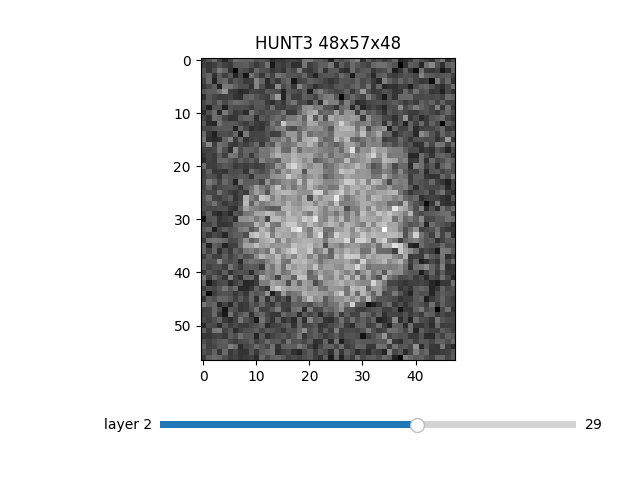

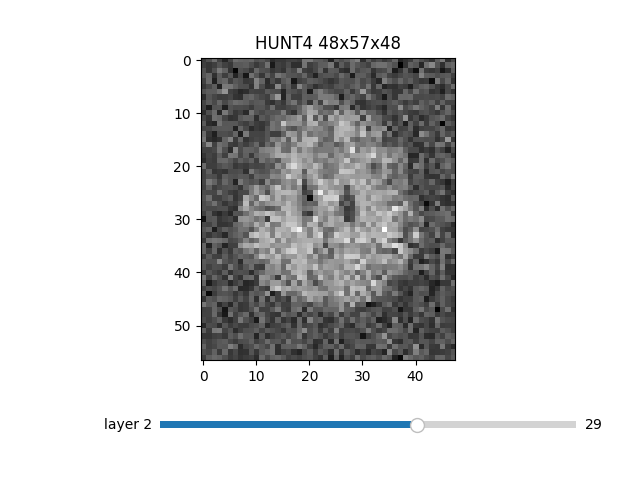

3: 0.9919349078575458


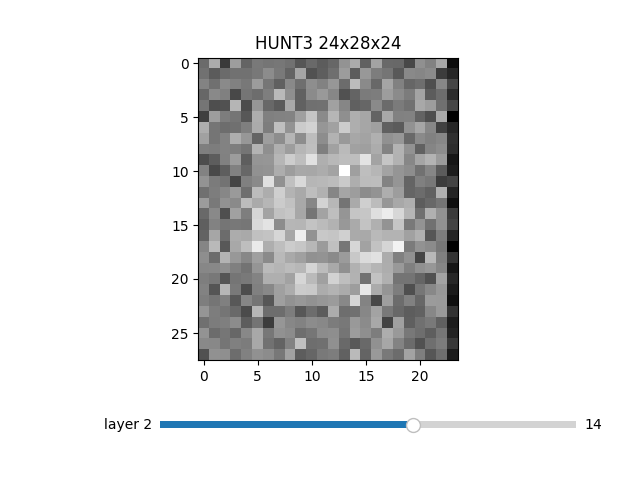

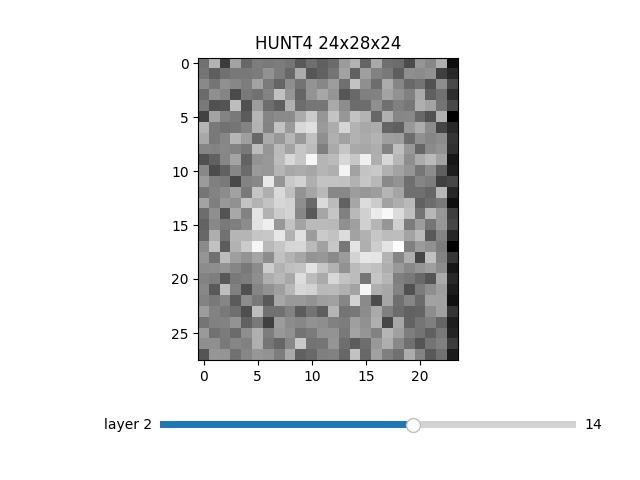

In [18]:
def compute_similarity_by_resizing_and_adding_noise(id="00046"):

    _n_hunt3 , mask_h3 = load_img_and_mask(id, 3)
    _n_hunt4 , mask_h4 = load_img_and_mask(id, 4)
    new_shape = _n_hunt3.shape[0]//2, _n_hunt3.shape[1]//2, _n_hunt3.shape[2]//2

    for i in range(4):
        if i > 0:
            new_shape = _n_hunt3.shape[0]//2, _n_hunt3.shape[1]//2, _n_hunt3.shape[2]//2
            _n_hunt3 = util.resize_3D_image(_n_hunt3, new_shape)
            _n_hunt4 = util.resize_3D_image(_n_hunt4, new_shape)
            _n_hunt3, _n_hunt4 = add_noise(_n_hunt3, _n_hunt4, mean=0.5, std=0.1, add=True, normalize=True)
        
        _metrics = util.compute_ssim(_n_hunt3, _n_hunt4)
        print(f"{i}: {_metrics}")

        str_size = 'x'.join([str(i) for i in new_shape])

        fc.imgshow_3D(f"HUNT3 {str_size}", _n_hunt3, current_plane=116//2**i)
        fc.imgshow_3D(f"HUNT4 {str_size}", _n_hunt4, current_plane=116//2**i)

compute_similarity_by_resizing_and_adding_noise("00046")